Homework 4

**Name:** Ephraim Rolingson  
**Course:** CPE 486/586  
**Instructor:** Dr. Rahul Bhadani  
**UAH Email:** er0060@uah.edu

**GitHub:** https://github.com/golddragongh/golddragon  
**GitHub Account:** https://github.com/golddragongh
**Package Version:** 0.1.5  
**Unique Package Keyword:** golddragon

**GitHub Commit Hash:** 322a1cb51c503cccd0b23ad9f336410c08ce21e3

In [2]:
import pandas as pd
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
df = pd.read_csv(url)
print(df)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


         AT      V       AP     RH      PE
0      8.34  40.77  1010.84  90.01  480.48
1     23.64  58.49  1011.40  74.20  445.75
2     29.74  56.90  1007.15  41.91  438.76
3     19.07  49.69  1007.22  76.79  453.09
4     11.80  40.66  1017.13  97.20  464.43
...     ...    ...      ...    ...     ...
9563  15.12  48.92  1011.80  72.93  462.59
9564  33.41  77.95  1010.30  59.72  432.90
9565  15.99  43.34  1014.20  78.66  465.96
9566  17.65  59.87  1018.58  94.65  450.93
9567  23.68  51.30  1011.86  71.24  451.67

[9568 rows x 5 columns]


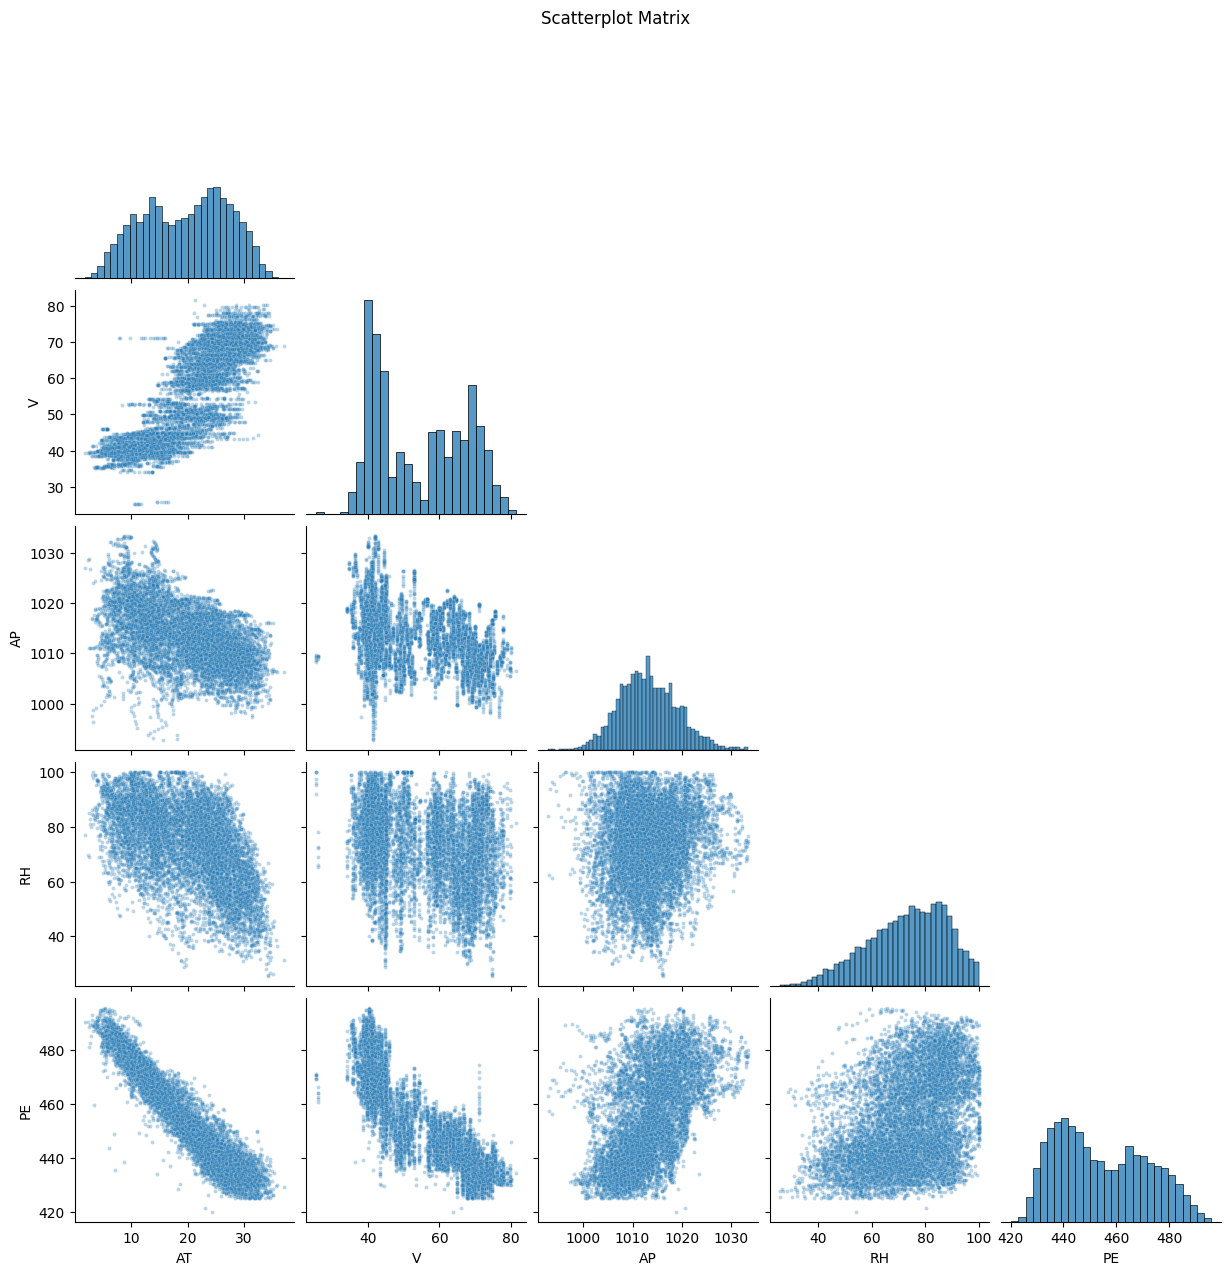

In [3]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch

sns.pairplot(df, corner=True, plot_kws={"alpha": 0.3, "s": 8})
plt.suptitle("Scatterplot Matrix", y=1.02)
plt.show()

In [4]:
X = df[["AT", "V", "AP", "RH"]].to_numpy(dtype=float)
y = df["PE"].to_numpy(dtype=float)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9568, 4)
y shape: (9568,)


In [5]:
%pip install --no-deps --force-reinstall "git+https://github.com/golddragongh/golddragon.git"

  Cloning https://github.com/golddragongh/golddragon.git to /tmp/pip-req-build-k88y0g5m
  Running command git clone --filter=blob:none --quiet https://github.com/golddragongh/golddragon.git /tmp/pip-req-build-k88y0g5m
  Resolved https://github.com/golddragongh/golddragon.git to commit 322a1cb51c503cccd0b23ad9f336410c08ce21e3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for golddragon: filename=golddragon-0.1.5-cp39-abi3-linux_x86_64.whl size=234576 sha256=bcfe604dba3ca55aaade01816c48b959e11f32712de94c87c23e6b797b2f8eaf
  Stored in directory: /tmp/pip-ephem-wheel-cache-p6ke172t/wheels/87/bc/30/77768b6697d8e91c1cb3a05e673259faab570c7b627f677d02
Successfully built golddragon
  Attempting uninstall: golddragon
    Found existing installation: golddragon 0.1.5
    Uninstalling golddragon-0.1.5:
      Successfully uninstalled golddragon-0.1.5


In [6]:
from golddragon.model.regression import CauchyRegression
from sklearn.model_selection import train_test_split

model = CauchyRegression(learning_rate=0.01, epochs=5000, c=1.0)
print(model)

CauchyRegression()


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42)
print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (7654, 4) (7654,)
Testing: (1914, 4) (1914,)


In [8]:
model.fit(X_train, y_train, X_test, y_test)
print("Final Cauchy Loss:", model.loss_history[-1])

Final Cauchy Loss: 1.1401345636634765


/usr/local/lib/python3.13/dist-packages/golddragon/model/regression.py:197: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  data = torch.tensor(data, dtype=torch.float64)


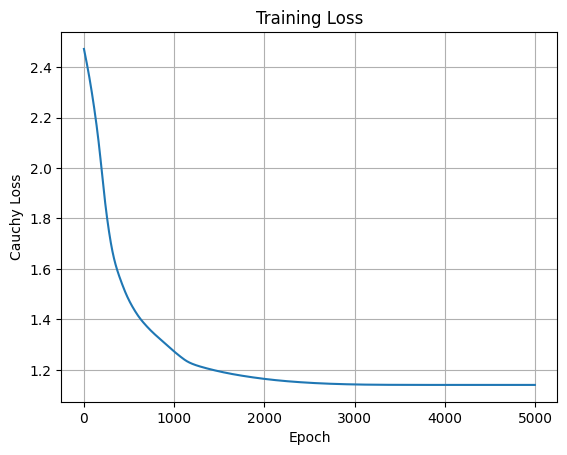

In [9]:
plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cauchy Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

In [10]:
with torch.no_grad():
    w = torch.stack([model.w1, model.w2, model.w3, model.w4])
    weights = w / model.x_std
    intercept = model.w0 - torch.sum(model.x_mean * weights)
    print(f"Intercept: {intercept.item():.6f}")
    for name, value in zip(["AT", "V", "AP", "RH"], weights):
        print(f"{name}: {value.item():.6f}")

Intercept: 515.069505
AT: -2.075632
V: -0.236854
AP: 0.003748
RH: -0.152342


A 95% confidence interval provides a range of plausible values for each population regression coefficient. It helps us evaluate the precision and uncertainty of our coefficient estimates. A narrower confidence interval indicates greater precision, while a wider interval indicates greater uncertainty.

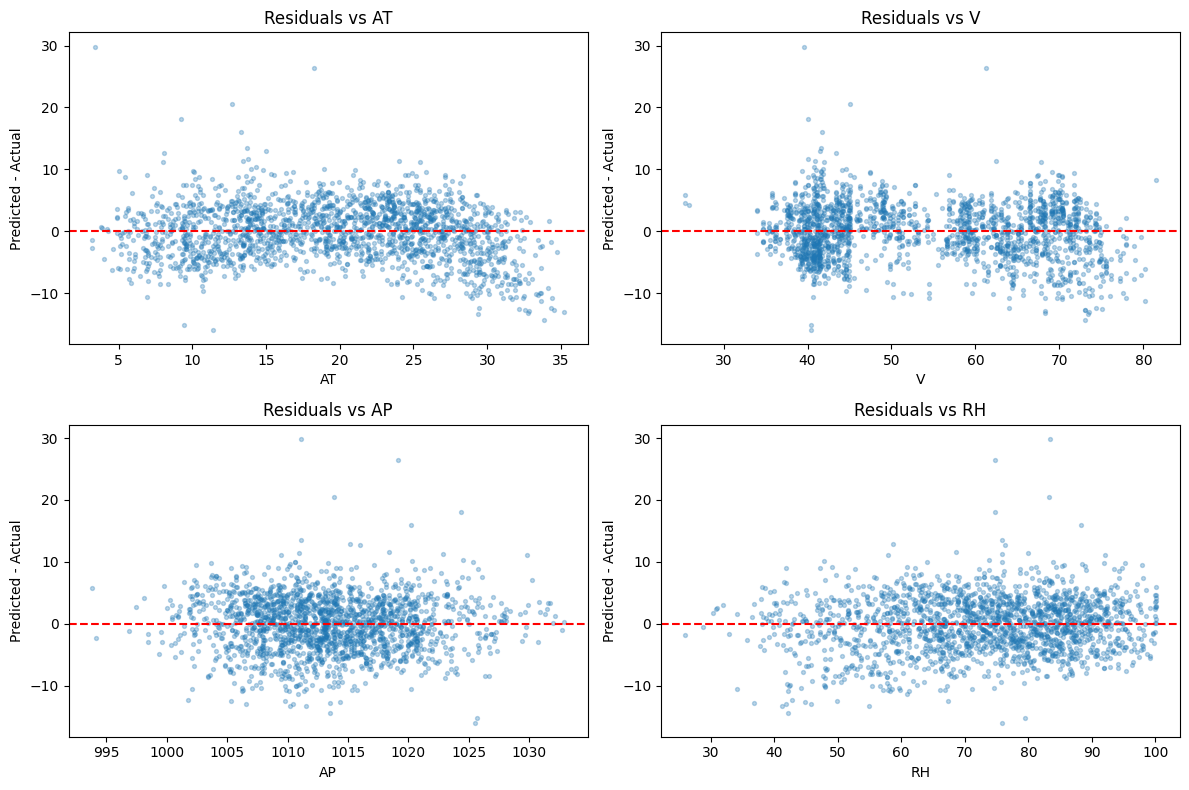

In [11]:
# Calculate predictions and residuals
y_pred = model.predict(X_test).detach().numpy()
residuals = y_pred - y_test

# Plot residuals against each feature
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

features = ["AT", "V", "AP", "RH"]

for i, ax in enumerate(axes.flat):
    ax.scatter(X_test[:, i], residuals, alpha=0.3, s=8)
    ax.axhline(0, color="red", linestyle="--")

    ax.set_xlabel(features[i])
    ax.set_ylabel("Predicted - Actual")
    ax.set_title(f"Residuals vs {features[i]}")

plt.tight_layout()
plt.show()

The residual plots show that most residuals are distributed around zero, indicating that the model captures much of the relationship between the input features and power output. However, some systematic patterns remain, particularly for ambient temperature (AT) and exhaust vacuum (V). This suggests that the linear model does not fully capture all relationships in the dataset and that nonlinear effects may be present.

In [12]:
from statsmodels.base.model import GenericLikelihoodModel
class CauchyModel(GenericLikelihoodModel):
    def nloglikeobs(self, params):
        y_pred = self.exog @ params
        residual = self.endog - y_pred
        c = 1.0
        loss = np.log(np.pi * c) + np.log1p((residual / c)**2)
        return loss

In [13]:
# Standardize inputs using the same values as PyTorch
X_scaled = (X_train - model.x_mean.numpy()) / model.x_std.numpy()

# Add intercept column
X_sm = np.column_stack([np.ones(len(X_scaled)), X_scaled])

# Use PyTorch coefficients as initial estimates
start = np.array([model.w0.item(), model.w1.item(), model.w2.item(), model.w3.item(), model.w4.item()])

# Fit the statsmodels Cauchy regression
sm_model = CauchyModel(y_train, X_sm)

result = sm_model.fit(start_params=start, method="bfgs", maxiter=300, disp=False)

print("Converged:", result.mle_retvals["converged"])
print("Fitted parameters:", result.params)

Converged: True
Fitted parameters: [ 4.54024462e+02 -1.55079535e+01 -3.01125295e+00  2.21380741e-02
 -2.21923090e+00]


In [14]:
# Extract PyTorch coefficients
pytorch_params = np.array([model.w0.item(), model.w1.item(), model.w2.item(), model.w3.item(), model.w4.item()])

# Compare both implementations
comparison = pd.DataFrame({"PyTorch": pytorch_params, "Statsmodels": result.params, "Difference": np.abs(pytorch_params - result.params)}, index=["w0", "w1", "w2", "w3", "w4"])
display(comparison)

,PyTorch,Statsmodels,Difference
w0,454.024462,454.024462,0.0
w1,-15.507954,-15.507954,0.0
w2,-3.011253,-3.011253,0.0
w3,0.022138,0.022138,0.0
w4,-2.219231,-2.219231,0.0


Dataset: EV Lithium-Ion Battery State of Charge

Source: Mendeley Data — EV Lithium-Ion Battery State of Charge Dataset

Link: https://data.mendeley.com/datasets/7dkmgbspfg/1

Authors: Venkataramana Veeramsetty, Keerthi Sri G. V., and Vinod Kumar D. M. (2026).

DOI: 10.17632/7dkmgbspfg.1

Dataset size: 604,750 observations.

Download instructions:

Open the dataset link above.

Click "Download All."

Extract the downloaded ZIP file if necessary.

Locate charging and discharging (1).xlsx.

Upload the Excel file to Google Colab using the Files sidebar, and ensure data is content folder.

This dataset will be used to train a binary logistic regression classifier for identifying low battery state of charge (SOC below 20%).

In [15]:
df_battery = pd.read_excel("/content/charging and discharging (1).xlsx")

print(df_battery.shape)
print(df_battery.columns.tolist())
display(df_battery.head())

(590336, 11)
['Cycle_Number', 'Cycle_Type', 'Time', 'Ambient_Temperature', 'Delta t ', 'Current_measured', 'Voltage_measured', 'Current_Mod', 'cummulative Ah', 'Ah', 'soc']


,Cycle_Number,Cycle_Type,Time,Ambient_Temperature,Delta t,Current_measured,Voltage_measured,Current_Mod,cummulative Ah,Ah,soc
0,1,charge,11.125,24,2.781,1.510817,4.012944,NaN,0.000754,0.001167,0.037707
1,1,charge,13.891,24,2.766,1.513170,4.018813,NaN,0.001917,0.001163,0.095838
2,1,charge,16.672,24,2.781,1.512649,4.023530,NaN,0.003085,0.001169,0.154264
3,1,charge,19.500,24,2.828,1.511927,4.028041,NaN,0.004273,0.001188,0.213649
4,1,charge,22.282,24,2.782,1.512427,4.031896,NaN,0.005442,0.001169,0.272088


In [16]:
for column in df_battery.columns:
    print(f"{column}: {df_battery[column].dtype}")

Cycle_Number: int64
Cycle_Type: str
Time: float64
Ambient_Temperature: int64
Delta t : float64
Current_measured: float64
Voltage_measured: float64
Current_Mod: float64
cummulative Ah: float64
Ah: float64
soc: float64


In [17]:
print(df_battery["soc"].describe())
print("\nUnique SOC values:", df_battery["soc"].nunique())
print("Missing SOC values:", df_battery["soc"].isna().sum())

count    590336.000000
mean         56.682343
std          23.127252
min          -0.530196
25%          43.428835
50%          62.139946
75%          72.239617
max         100.943829
Name: soc, dtype: float64

Unique SOC values: 590008
Missing SOC values: 0


In [18]:
# Remove invalid SOC measurements
df_battery = df_battery[df_battery["soc"].between(0, 100)].copy()

# Create binary classification labels
df_battery["Low_SOC"] = (df_battery["soc"] < 20).astype(int)

# Check class imbalance
print(df_battery["Low_SOC"].value_counts())
print(df_battery["Low_SOC"].value_counts(normalize=True) * 100)

Low_SOC
0    527590
1     62244
Name: count, dtype: int64
Low_SOC
0    89.4472
1    10.5528
Name: proportion, dtype: float64


In [19]:
features = ["Voltage_measured", "Current_measured", "Ambient_Temperature", "Delta t "]

X = df_battery[features]
y = df_battery["Low_SOC"]

print("Input features:", X.shape)
print("Target labels:", y.shape)

print("\nMissing values:")
print(X.isna().sum())

display(X.head())

Input features: (589834, 4)
Target labels: (589834,)

Missing values:
Voltage_measured       0
Current_measured       0
Ambient_Temperature    0
Delta t                0
dtype: int64


,Voltage_measured,Current_measured,Ambient_Temperature,Delta t
0,4.012944,1.510817,24,2.781
1,4.018813,1.513170,24,2.766
2,4.023530,1.512649,24,2.781
3,4.028041,1.511927,24,2.828
4,4.031896,1.512427,24,2.782


In [20]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)

train_idx, test_idx = next(splitter.split(X, y, groups=df_battery["Cycle_Number"]))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining class percentages:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class percentages:")
print(y_test.value_counts(normalize=True) * 100)

Training: (459031, 4)
Testing: (130803, 4)

Training class percentages:
Low_SOC
0    89.429254
1    10.570746
Name: proportion, dtype: float64

Testing class percentages:
Low_SOC
0    89.510179
1    10.489821
Name: proportion, dtype: float64


In [21]:
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()

# Fit scaler using training data only
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)

# Apply same transformation to testing data
X_test_scaled = scaler.transform(X_test).astype(np.float32)

print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)
print("Feature means:", X_train_scaled.mean(axis=0))
print("Feature std:", X_train_scaled.std(axis=0))

Training: (459031, 4)
Testing: (130803, 4)
Feature means: [ 4.2548871e-09  3.1911651e-09  0.0000000e+00 -1.0637218e-09]
Feature std: [1. 1. 0. 1.]


In [23]:
from golddragon.model.logit import LogisticRegression

model_logit = LogisticRegression(learning_rate=0.05, epochs=30, batch_size=1024)
model_logit.fit(X_train_scaled, y_train)

print("Final Training Loss:", model_logit.loss_history[-1])

/usr/local/lib/python3.13/dist-packages/golddragon/model/logit.py:32: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:208.)
  y_train = torch.as_tensor(np.asarray(y_train), dtype=torch.float32).reshape(-1)


Final Training Loss: 0.40865725350456267


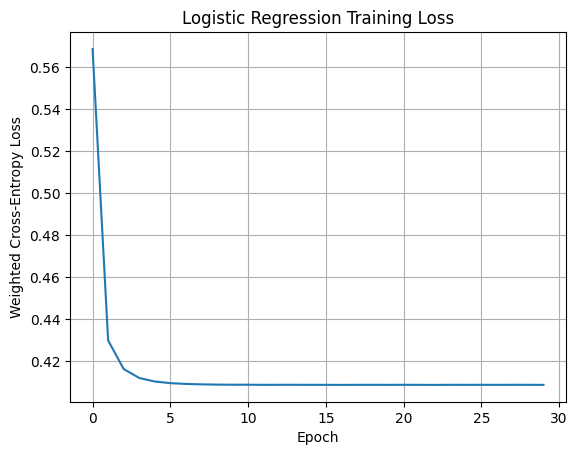

In [24]:
plt.plot(model_logit.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Weighted Cross-Entropy Loss")
plt.title("Logistic Regression Training Loss")
plt.grid(True)
plt.show()

In [26]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix)

# Predict using test data
y_pred = model_logit.predict(X_test_scaled).cpu().numpy()
y_prob = model_logit.predict_proba(X_test_scaled).cpu().numpy()

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8669984633379968
Precision: 0.43997387328543436
Recall: 0.9818526346476204
ROC AUC: 0.9736204216532202

Confusion Matrix:
[[99934 17148]
 [  249 13472]]


The logistic regression model achieved an accuracy of 86.70%, precision of 44.00%, recall of 98.19%, and ROC AUC of 97.36%.

The high recall shows that the model successfully identifies nearly all low SOC observations. This is useful for battery management systems because failing to identify a low SOC condition could affect battery operation.

However, the relatively low precision indicates that the model frequently classifies normal SOC observations as low SOC. This may lead to unnecessary warnings.

The weighted cross-entropy loss helped account for the class imbalance by emphasizing low SOC observations.

Dataset Features and Classification Objective

This project uses real world lithium ion battery charging and discharging measurements to train a logistic regression classifier.

Input Features:

Voltage_measured: Measured battery terminal voltage.

Current_measured: Measured battery current during charging or discharging.

Ambient_Temperature: Surrounding environmental temperature.

Delta t: Time interval associated with each measurement.

Classification Labels:

0 — Normal SOC: Battery state of charge is at least 20%.

1 — Low SOC: Battery state of charge is below 20%.

The binary labels were generated from the dataset's SOC measurements. Invalid SOC values outside 0–100% were excluded.

My objective was to determine whether a lithium ion battery is operating below 20% SOC using measured electrical and environmental features. Logistic regression estimates the probability of a low SOC condition, which could be useful for battery monitoring and energy management systems.

AI Usage Reflection

I used ChatGPT to help me understand and complete parts of this assignment. Some of my prompts included "How to implement this like my linear regression?" and "What do I do next?" I primarily used it to understand the implementation of Cauchy loss, troubleshoot PyTorch errors, and learn how to evaluate my regression and classification models.

Without AI, I would have referred to my lecture notes, PyTorch documentation, and online programming examples. I would have derived the necessary equations, implemented the models, and debugged the code by examining error messages and testing individual functions.